<a href="https://colab.research.google.com/github/MichaelCM7/SemProject_MLEngine/blob/main/Model_Base.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Identifying the ML approach, relevant algorithms to the dataset and the expected output of your application

The application will be using a **CNN** for **classifying** images of crops to identify the specific crop diseases or pest present and provide a remedy. The dataset has images of the crop disease and the appropriate label, thus **supervised learning** will work best for this scenario. The model will be returning the **name of the crop disease or pest** and a **confidence score** which will be used on a mapping that will return the remedy.


## The data cleaning process beginning from exploration to the final dataset for modelling

The dataset used was the [Crop Diseases Classification](https://www.kaggle.com/datasets/mexwell/crop-diseases-classification) dataset, obtained from the Kaggle Website.

### Installation of the Kaggle Dataset

In [1]:
import os
from google.colab import files
from google.colab import userdata

# Use the Kaggle API Key and Kaggle Username in the secrets panel
os.environ['KAGGLE_USERNAME'] = userdata.get('KAGGLE_USERNAME')
os.environ['KAGGLE_KEY'] = userdata.get('KAGGLE_API_KEY')

# Download the dataset from Kaggle and unzip the downloaded folder
!kaggle datasets download -d mexwell/crop-diseases-classification
!unzip -q crop-diseases-classification.zip -d ./dataset

Dataset URL: https://www.kaggle.com/datasets/mexwell/crop-diseases-classification
License(s): other
100% 2.00G/2.00G [01:34<00:00, 22.8MB/s]



### Data Cleaning Process



In [2]:
!pip install imagehash

#### Core Imports

In [3]:
import os
import json
import cv2
import imagehash
from PIL import Image
import pandas as pd

#### Finding the file in Colab's directories and using them for data cleaning

In [4]:
# Dynamically build file index
image_path_map = {}
csv_path = None
json_path = None

# Searches the dataset folder for the train.csv and label_num_to_disease_map.json
for root, dirs, files in os.walk("./dataset"):
    if 'train.csv' in files:
        csv_path = os.path.join(root, 'train.csv') # Updates csv_path variable to absolute path
    if 'label_num_to_disease_map.json' in files:
        json_path = os.path.join(root, 'label_num_to_disease_map.json') # Updates json_path variable to absolute path
    for f in files:
        if f.lower().endswith(('.jpg', '.png', '.jpeg')):
            image_path_map[f] = os.path.join(root, f) # Map each relatve path to its absolute one


#### Uncleaned Data Shape

In [5]:
uncleaned_data = pd.read_csv(csv_path)
print(f"Data Shape: {uncleaned_data.shape}")

Data Shape: (21397, 2)


#### Loading the correct mappings and labels

In [6]:
# Load correct csv & label mapping
df = pd.read_csv(csv_path)
with open(json_path, 'r') as f:
    label_map = json.load(f)

# Finds image file paths
def get_path(img_id):
    name = str(img_id).strip()
    if name in image_path_map:
        return image_path_map[name]
    elif f"{name}.jpg" in image_path_map:
        return image_path_map[f"{name}.jpg"]
    return None

df['filepath'] = df['image_id'].apply(get_path)

#### Checking for missing images, corrupt files, blurry images and duplicates

In [7]:
# Clean and Check images for corruption, blur and Duplicates
clean_rows = []
seen_hashes = set()  # Make lookup speed faster and helps improve performance of duplicate finding
blur_threshold = 100.0  # Blur level to check for is hash results

for idx, row in df.iterrows():
    fpath = row['filepath']

    # Check if the file exists or if it is corrupt
    if not fpath or not os.path.exists(fpath):
        continue
    try:
        img = Image.open(fpath)
        img.verify()
        img = Image.open(fpath)
    except Exception:
        continue  # Skip corrupted image

    # Checks for blurry images
    img_cv = cv2.imread(fpath, cv2.IMREAD_GRAYSCALE)
    if img_cv is None or cv2.Laplacian(img_cv, cv2.CV_64F).var() < blur_threshold:
        continue  # Skip blurry image

    # Optimized Duplicate Detection to decrease processing time from an hour to ~5 mins
    h_str = str(imagehash.phash(img))
    if h_str in seen_hashes:
        continue  # Skip duplicate image

    seen_hashes.add(h_str)

    # If all checks pass, keep the record
    row_dict = row.to_dict()
    row_dict['disease_name'] = label_map.get(str(row['label']), "Unknown")
    clean_rows.append(row_dict)

#### Export the cleaned CSV file

In [8]:
# Create a new DataFrame to add
clean_df = pd.DataFrame(clean_rows)
print("The data has successfully been cleaned")

print(f"Total entries in CSV: {len(df)}")
print(f"Clean, unique images: {len(clean_df)}")

# Export cleaned data to a CSV file
output_csv_path = "./clean_train.csv"
clean_df.to_csv(output_csv_path, index=False)
print(f"Saved clean dataset to {output_csv_path}")

The data has successfully been cleaned
Total entries in CSV: 21397
Clean, unique images: 17607
Saved clean dataset to ./clean_train.csv


### Exploratory Data Analysis

In [9]:
clean_dataset_csv_path = "./clean_train.csv"
cleaned_csv_df = pd.read_csv(clean_dataset_csv_path)
cleaned_csv_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17607 entries, 0 to 17606
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   image_id      17607 non-null  object
 1   label         17607 non-null  int64 
 2   filepath      17607 non-null  object
 3   disease_name  17607 non-null  object
dtypes: int64(1), object(3)
memory usage: 550.3+ KB


#### Finding The Data Distribution

Each crop disease class has its images counted and the percentages derived. This will help with understanding the datasets data distribution per class, and determine the bias of the model later on.

DISEASE DISTRIBUTION IN CLEAN DATASET
                                     Count  Percentage (%)
disease_name                                              
Cassava Mosaic Disease (CMD)         10934           62.10
Healthy                               2076           11.79
Cassava Green Mottle (CGM)            1961           11.14
Cassava Brown Streak Disease (CBSD)   1757            9.98
Cassava Bacterial Blight (CBB)         879            4.99




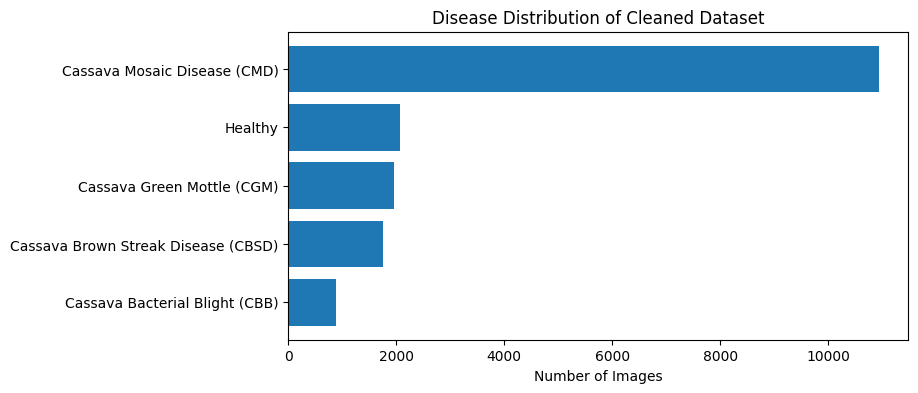

In [10]:
import matplotlib.pyplot as plt

# Get data counts and percentages
counts = cleaned_csv_df['disease_name'].value_counts()
percentages = cleaned_csv_df['disease_name'].value_counts(normalize=True) * 100

# Combine count and numbers into one dataframe
distribution_df = pd.DataFrame({
    'Count': counts,
    'Percentage (%)': percentages.round(2)
})

print("DISEASE DISTRIBUTION IN CLEAN DATASET")
print(distribution_df)

print("\n")

# Show distribution in bar graph
plt.figure(figsize=(8, 4))
bars = plt.barh(distribution_df.index, distribution_df['Count'])
plt.xlabel('Number of Images')
plt.title('Disease Distribution of Cleaned Dataset')
plt.gca().invert_yaxis()  # Display in ascending order
plt.show()

#### Data Discovery Results


- The dataset is unevenly distributed with Cassava Mosaic Disease having approximately 60% of the data
- Disease like Cassava Bacterial Blight are highly under represented making up approximately 5% of the data
- The images all use the standard RGB colour format
- The images are not of the same standard dimensions and thus the images will need to be trimmed into a uniform square before training of the CNN begins

## Modelling approach taken on the CNN model

The CNN model will be using **Depthwise Separable (DS) Convolutions**  and **Squeeze and Excitation (SE) Attention Modules** to capture the features in the **SEDS Convolution Block**. SEDS was chosen over the standard concolution method since it improves performace. It will also compress the features through global pooling to reduce the chances of overfitting and use the AdamW optimizer to tune the models weights.  

### Validation
The dataset will be split with 80% used for training and 20% used for validating the model with a manual seed of 42 for reproducibility. It also uses a weighted random sampler to ensure that the model performs well across the other under-represented classes.

### Training and Evaluation

In [11]:
import json
import torch
import torch.nn as nn
import torch.optim as optim
import pandas as pd
from PIL import Image
from torch.utils.data import Dataset, DataLoader, random_split, WeightedRandomSampler
from torchvision import transforms
from sklearn.metrics import classification_report

# Enable fast TF32 matrix multiplication and cuDNN autotuning
torch.set_float32_matmul_precision('high')
torch.backends.cudnn.benchmark = True

# Define Graphing Variables
train_losses = []
test_losses = []
train_correct = []
test_correct = []

# 1. Dataset Class
class FilteredCropDataset(Dataset):
    def __init__(self, df, json_path, img_map, transform=None):
        self.df = df.reset_index(drop=True)
        self.img_map = img_map
        self.transform = transform

        with open(json_path, 'r') as f:
            self.label_map = json.load(f)

        self.classes = [self.label_map[str(i)] for i in sorted(map(int, self.label_map.keys()))]

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img_name = str(row['image_id']).strip()

        img_path = self.img_map.get(img_name, self.img_map.get(f"{img_name}.jpg"))

        image = Image.open(img_path).convert('RGB')
        label = int(row['label'])

        if self.transform:
            image = self.transform(image)

        return image, label

# 2. Optimized 224x224 Transforms
img_size = 224
batch_size = 64

train_transform = transforms.Compose([
    transforms.Resize((img_size, img_size)),
    transforms.RandomCrop(img_size, padding=8, padding_mode='edge'),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.15, contrast=0.15),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

val_transform = transforms.Compose([
    transforms.Resize((img_size, img_size)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

train_dataset_full = FilteredCropDataset(clean_df, json_path, image_path_map, transform=train_transform)
val_dataset_full = FilteredCropDataset(clean_df, json_path, image_path_map, transform=val_transform)

train_size = int(0.8 * len(train_dataset_full))
val_size = len(train_dataset_full) - train_size

generator = torch.Generator().manual_seed(42)
train_dataset, _ = random_split(train_dataset_full, [train_size, val_size], generator=generator)
_, val_dataset = random_split(val_dataset_full, [train_size, val_size], generator=generator)

# --- Mild Smoothed Sampler ---
train_indices = train_dataset.indices
train_targets = [int(train_dataset_full.df.iloc[idx]['label']) for idx in train_indices]

class_counts = torch.bincount(torch.tensor(train_targets))
class_weights_sampler = 1.0 / (class_counts.float() ** 0.5)
sample_weights = [class_weights_sampler[t] for t in train_targets]

sampler = WeightedRandomSampler(
    weights=sample_weights,
    num_samples=len(sample_weights),
    replacement=True
)

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    sampler=sampler,
    num_workers=2,
    pin_memory=True,
    persistent_workers=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
    persistent_workers=True
)

# 3. Depthwise Separable Conv + Squeeze-and-Excitation Module
class SEDSConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super(SEDSConvBlock, self).__init__()
        self.conv = nn.Sequential(
            # Depthwise Convolution
            nn.Conv2d(in_channels, in_channels, kernel_size=3, padding=1, groups=in_channels, bias=False),
            nn.BatchNorm2d(in_channels),
            nn.SiLU(),

            # Pointwise Convolution
            nn.Conv2d(in_channels, out_channels, kernel_size=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.SiLU()
        )

        # Squeeze-and-Excitation Attention
        self.se = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Conv2d(out_channels, max(1, out_channels // 4), kernel_size=1),
            nn.SiLU(),
            nn.Conv2d(max(1, out_channels // 4), out_channels, kernel_size=1),
            nn.Sigmoid()
        )

    def forward(self, x):
        x = self.conv(x)
        weight = self.se(x)
        return x * weight

# 4. Optimized Architecture with GAP
class FullyOptimizedCropCNN(nn.Module):
    def __init__(self, num_classes):
        super(FullyOptimizedCropCNN, self).__init__()
        self.features = nn.Sequential(
            # Stem: Initial convolution (224x224 -> 112x112)
            nn.Conv2d(3, 32, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.SiLU(),
            nn.MaxPool2d(2, 2),

            # Block 1: 112x112 -> 56x56
            SEDSConvBlock(32, 64),
            nn.MaxPool2d(2, 2),

            # Block 2: 56x56 -> 28x28
            SEDSConvBlock(64, 128),
            nn.MaxPool2d(2, 2),

            # Block 3: 28x28 -> 14x14
            SEDSConvBlock(128, 256),
            nn.MaxPool2d(2, 2),

            # Block 4: 14x14 -> 1x1
            SEDSConvBlock(256, 256),
            nn.AdaptiveAvgPool2d((1, 1))
        )
        self.classifier = nn.Sequential(
            nn.Dropout(0.4),
            nn.Linear(256, 128),
            nn.SiLU(),
            nn.Dropout(0.2),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = torch.flatten(x, 1)
        x = self.classifier(x)
        return x

num_classes = len(train_dataset_full.classes)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Instantiate model and transfer to GPU using channels_last memory layout
model = FullyOptimizedCropCNN(num_classes).to(device, memory_format=torch.channels_last)

# Optional Kernel Fusion via PyTorch 2.x compile
try:
    model = torch.compile(model)
    print("✓ Model compiled with torch.compile()")
except Exception as e:
    print("Running standard PyTorch execution without compilation")

# Label smoothing prevents overconfidence
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer = optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-3)

epochs = 50
scheduler = optim.lr_scheduler.OneCycleLR(
    optimizer,
    max_lr=3.5e-3,
    steps_per_epoch=len(train_loader),
    epochs=epochs,
    pct_start=0.3
)

scaler = torch.amp.GradScaler('cuda')

# 5. Fast Training Loop
best_val_acc = 0.0

print(f"Starting training on {device} for {epochs} epochs at 224x224 resolution...\n")

for epoch in range(epochs):
    model.train()
    running_train_loss = 0.0
    train_correct_count = 0

    for inputs, labels in train_loader:
        # Load tensors using channels_last layout for GPU acceleration
        inputs = inputs.to(device, memory_format=torch.channels_last, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        # Fast zeroing out without allocation overhead
        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast('cuda'):
            outputs = model(inputs)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()

        # Gradient Clipping for Training Stability
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

        scaler.step(optimizer)
        scaler.update()

        scheduler.step()

        running_train_loss += loss.item() * inputs.size(0)
        train_correct_count += (outputs.argmax(1) == labels).sum().item()

    # Calculate training epoch metrics
    epoch_train_loss = running_train_loss / train_size
    train_acc = train_correct_count / train_size

    model.eval()
    running_val_loss = 0.0
    val_correct_count = 0

    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs = inputs.to(device, memory_format=torch.channels_last, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            with torch.amp.autocast('cuda'):
                outputs = model(inputs)
                loss = criterion(outputs, labels)

            running_val_loss += loss.item() * inputs.size(0)
            val_correct_count += (outputs.argmax(1) == labels).sum().item()

    # Calculate validation epoch metrics
    epoch_val_loss = running_val_loss / val_size
    val_acc = val_correct_count / val_size

    # Append metrics to global lists for graphing
    train_losses.append(epoch_train_loss)
    test_losses.append(epoch_val_loss)
    train_correct.append(train_acc)
    test_correct.append(val_acc)

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), "best_crop_model.pth")
        saved_flag = " (Model Saved)"
    else:
        saved_flag = ""

    print(f"Epoch {epoch+1:02d}/{epochs} | "
          f"Train Loss: {epoch_train_loss:.4f} | "
          f"Val Loss: {epoch_val_loss:.4f} | "
          f"Train Acc: {train_acc:.4f} | "
          f"Val Acc: {val_acc:.4f}{saved_flag}")

print(f"\nTraining Complete! Best Validation Accuracy: {best_val_acc:.4f}\n")

# 6. Classification Report
print("--- PER-CLASS PERFORMANCE ANALYSIS ---")
model.load_state_dict(torch.load("best_crop_model.pth"))
model.eval()

all_preds, all_labels = [], []
with torch.no_grad():
    for inputs, labels in val_loader:
        inputs = inputs.to(device, memory_format=torch.channels_last)
        with torch.amp.autocast('cuda'):
            outputs = model(inputs)
        all_preds.extend(outputs.argmax(1).cpu().numpy())
        all_labels.extend(labels.numpy())

print(classification_report(all_labels, all_preds, target_names=train_dataset_full.classes))

✓ Model compiled with torch.compile()
Starting training on cuda for 50 epochs at 224x224 resolution...



W1031 14:21:39.754000 3375 torch/_inductor/utils.py:1731] [0/0] Not enough SMs to use max_autotune_gemm mode


Epoch 01/50 | Train Loss: 1.4666 | Val Loss: 1.1199 | Train Acc: 0.4111 | Val Acc: 0.6425 (Model Saved)
Epoch 02/50 | Train Loss: 1.3209 | Val Loss: 1.0671 | Train Acc: 0.4853 | Val Acc: 0.6624 (Model Saved)
Epoch 03/50 | Train Loss: 1.2389 | Val Loss: 1.0057 | Train Acc: 0.5329 | Val Acc: 0.6755 (Model Saved)
Epoch 04/50 | Train Loss: 1.1876 | Val Loss: 0.9512 | Train Acc: 0.5721 | Val Acc: 0.7050 (Model Saved)
Epoch 05/50 | Train Loss: 1.1410 | Val Loss: 0.9494 | Train Acc: 0.5977 | Val Acc: 0.7235 (Model Saved)
Epoch 06/50 | Train Loss: 1.1088 | Val Loss: 0.9733 | Train Acc: 0.6173 | Val Acc: 0.7121
Epoch 07/50 | Train Loss: 1.0837 | Val Loss: 0.8899 | Train Acc: 0.6332 | Val Acc: 0.7416 (Model Saved)
Epoch 08/50 | Train Loss: 1.0483 | Val Loss: 0.9029 | Train Acc: 0.6598 | Val Acc: 0.7535 (Model Saved)
Epoch 09/50 | Train Loss: 1.0299 | Val Loss: 0.8766 | Train Acc: 0.6681 | Val Acc: 0.7592 (Model Saved)
Epoch 10/50 | Train Loss: 1.0109 | Val Loss: 0.9815 | Train Acc: 0.6799 | Val 

### Manual Accuracy Test

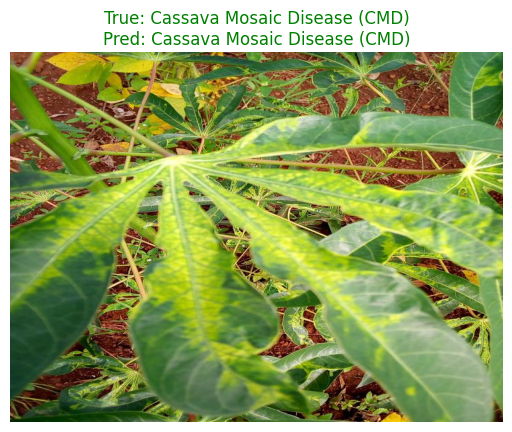

In [12]:
import random

# Pick a random test image
idx = random.randint(0, len(val_dataset_full) - 1)
img_tensor, true_idx = val_dataset_full[idx]

# Get Model Prediction
model.eval()
with torch.no_grad():
    input_batch = img_tensor.unsqueeze(0).to(device)
    outputs = model(input_batch)
    pred_idx = outputs.argmax(1).item()

# Get Class Names
true_name = train_dataset_full.classes[true_idx]
pred_name = train_dataset_full.classes[pred_idx]

# Display Image and Result
img_path = val_dataset_full.img_map.get(str(val_dataset_full.df.iloc[idx]['image_id']).strip())
plt.imshow(Image.open(img_path))
plt.title(f"True: {true_name}\nPred: {pred_name}", color=('green' if true_idx == pred_idx else 'red'))
plt.axis('off')
plt.show()

### Plot Results

In [13]:
!pip install matplotlib -q

In [ ]:
import matplotlib.pyplot as plt
%matplotlib inline


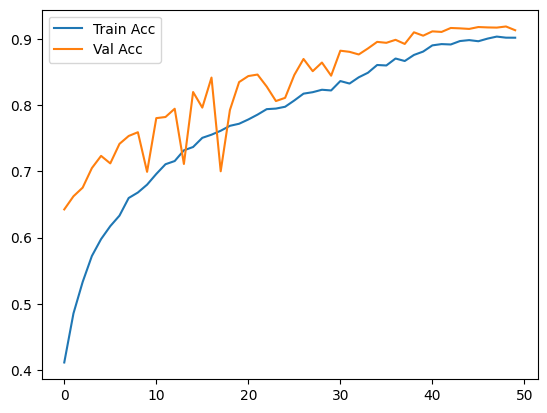

In [15]:
# Plot Training vs Validation Accuracy
plt.plot(train_correct, label='Train Acc')
plt.plot(test_correct, label='Val Acc')
plt.legend()
plt.show()

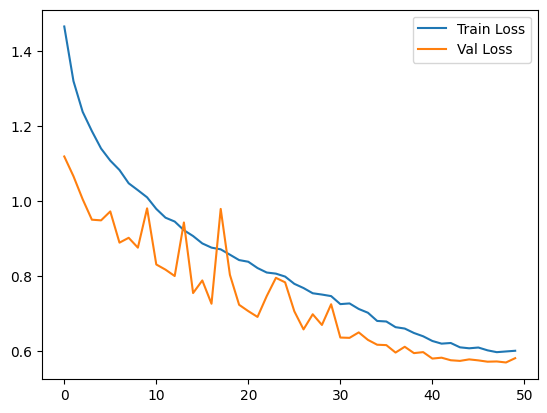

In [16]:
# Plot Training vs Validation Loss
plt.plot(train_losses, label='Train Loss')
plt.plot(test_losses, label='Val Loss')
plt.legend()
plt.show()

Export Model WIth ONNX

In [17]:
!pip install onnx onnxscript -q

import torch
from google.colab import files

# 1. Unwrap Dynamo/torch.compile wrapper if it exists
raw_model = model._orig_mod if hasattr(model, '_orig_mod') else model

# 2. Move unwrapped model to CPU and restore contiguous layout
raw_model = raw_model.to(device='cpu', memory_format=torch.contiguous_format)
raw_model.eval()

# 3. Create dummy input on CPU (224x224)
dummy_input = torch.randn(1, 3, 224, 224)
onnx_filename = "crop_disease_model.onnx"
labels_filename = "labels.txt"

# 4. Export safely using the raw, un-compiled model
torch.onnx.export(
    raw_model,
    dummy_input,
    onnx_filename,
    export_params=True,
    opset_version=14,
    do_constant_folding=True,
    input_names=['input'],
    output_names=['output'],
    dynamic_axes={'input': {0: 'batch_size'}, 'output': {0: 'batch_size'}},
    dynamo=False
)

print("✓ ONNX model exported cleanly!")

# 5. Save class labels file
classes = train_dataset_full.classes

with open(labels_filename, 'w') as f:
    for cls in classes:
        f.write(f"{cls}\n")

print("\nKotlin Class Labels saved to labels.txt:")
for idx, cls_name in enumerate(classes):
    print(f"  Index {idx}: {cls_name}")

# 6. Download files to local machine
files.download(onnx_filename)
files.download(labels_filename)

/tmp/ipykernel_3375/2812066193.py:19: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(


✓ ONNX model exported cleanly!

Kotlin Class Labels saved to labels.txt:
  Index 0: Cassava Bacterial Blight (CBB)
  Index 1: Cassava Brown Streak Disease (CBSD)
  Index 2: Cassava Green Mottle (CGM)
  Index 3: Cassava Mosaic Disease (CMD)
  Index 4: Healthy


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Other methods used to validate the results of the base model

Numerous methods were explored along the way, such as:
| Architecture / Method | Configuration / Parameters | Best Result (Accuracy) |
| :--- | :--- | :---: |
| **Standard CNN**    | $128 \times 128$ block sizes, Low epochs (20) | 0.45 |
| **Standard CNN**    | $224 \times 224$ block sizes, Low epochs (20) | 0.68 |
| **Standard CNN**    | $128 \times 128$ block sizes, High learning rates, low epochs (10–20) | 0.64 |
| **Standard CNN**    | $128 \times 128$ block sizes, Low learning rates, high epochs (30+) | 0.84 |
| **SEDS Architecture**    | $128 \times 128$ block sizes, Moderate epochs (25) | 0.77 |
| **SEDS Architecture**    | $224 \times 224$ block sizes, High epochs (30+) | **0.91** |
| **Knowledge Distillation**    | $224 \times 224$ block sizes, EfficientNet-B0 as post-trained teacher for smaller CNN | 0.87 |

The model's validation scores proved that each architecture yeilds vastly different results. Based on the tests done, the validation scores proved to be consistent to their capabilities.  
